# Самостоятельная работа: методы отбора признаков

**Цель:** не просто запустить методы отбора, а понять, **когда** они полезны, **какие признаки** сохраняют и **как** корректно оценивать их эффект.

В этой работе вы будете сравнивать методы отбора признаков на одной задаче классификации, исследовать коррелированные и шумовые признаки, проверять устойчивость отбора и находить ошибки в схеме эксперимента.

**Итог:** таблица результатов, 2–3 графика, выводы о наиболее удачном способе отбора. Отвечайте на вопросы прямо в Markdown-ячейках.

> Не подменяйте отбор признаков оценкой важности: высокая важность в одной модели не означает, что признак обязательно полезен для любой модели.

## Маршрут работы и оценивание

| Часть | Что исследуем | Баллы |
|---|---|---:|
| 1. Базовая модель | Исходные признаки и метрика | 10 |
| 2. Filter | Дисперсия, корреляция, ANOVA, MI | 25 |
| 3. Wrapper | RFE и цена вычислений | 15 |
| 4. Embedded | L1-регуляризация | 15 |
| 5. Честное сравнение | Pipeline, CV, качество и время | 15 |
| 6. Утечка данных | Ошибка и корректный эксперимент | 10 |
| 7. Исследовательский мини-кейс | Устойчивость выбора признаков | 10 |
| **Итого** | | **100** |

**Правила:** фиксируйте `random_state`; для каждого метода используйте одинаковые разбиения; при кросс-валидации обучайте отбор *внутри* `Pipeline`. К финальному тесту обращайтесь только после выбора подхода.

In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
    RFE, SelectFromModel
)
from sklearn.metrics import roc_auc_score, classification_report
from functools import partial

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pd.set_option('display.max_columns', 40)
print('Импорты выполнены')

Импорты выполнены


## Данные и постановка задачи

Используем открытый набор **Breast Cancer Wisconsin**, встроенный в scikit-learn: 569 наблюдений, 30 числовых признаков, бинарный целевой признак.

Чтобы исследовать работу методов отбора, специально добавим:
- 8 независимых шумовых признаков;
- 2 почти дублирующих исходные признаки;
- 1 константный признак.

**Важно:** здесь шум и дубликаты добавлены нами, поэтому можно проверить, способен ли алгоритм их обнаружить.

In [9]:
data = load_breast_cancer(as_frame=True)
X_original = data.data.copy()
y = data.target.copy()

rng = np.random.default_rng(RANDOM_STATE)
X = X_original.copy()
for j in range(8):
    X[f'noise_{j + 1}'] = rng.normal(size=len(X))
X['duplicate_mean_radius'] = X['mean radius'] + rng.normal(0, 0.02, len(X))
X['duplicate_mean_texture'] = X['mean texture'] + rng.normal(0, 0.02, len(X))
X['constant_feature'] = 1.0

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print('Общий набор:', X.shape, '| train:', X_train.shape, '| test:', X_test.shape)
print('Классы (доля класса 1):', y.value_counts(normalize=True).round(3).to_dict())
display(X_train.head(3))

Общий набор: (569, 41) | train: (426, 41) | test: (143, 41)
Классы (доля класса 1): {1: 0.627, 0: 0.373}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,noise_1,noise_2,noise_3,noise_4,noise_5,noise_6,noise_7,noise_8,duplicate_mean_radius,duplicate_mean_texture,constant_feature
517,19.89,20.26,130.50,1214.0,0.10370,0.13100,0.1411,0.09431,0.1802,0.06188,0.5079,0.8737,3.654,59.70,0.005089,0.02303,0.03052,0.011780,0.01057,0.003391,...,25.23,160.5,1646.0,0.14170,0.3309,0.4185,0.16130,0.2549,0.09136,-0.688372,-1.398110,-1.567177,-1.099658,-0.516298,0.215508,0.755252,-1.488057,19.914399,20.267278,1.0
287,12.89,13.12,81.89,515.9,0.06955,0.03729,0.0226,0.01171,0.1337,0.05581,0.1532,0.4690,1.115,12.68,0.004731,0.01345,0.01652,0.005905,0.01619,0.002081,...,15.54,87.4,577.0,0.09616,0.1147,0.1186,0.05366,0.2309,0.06915,0.052467,0.336583,-0.911444,0.087868,1.682384,0.051832,-0.891529,-1.271249,12.898072,13.098295,1.0
25,17.14,16.40,116.00,912.7,0.11860,0.22760,0.2229,0.14010,0.3040,0.07413,1.0460,0.9760,7.276,111.40,0.008029,0.03799,0.03732,0.023970,0.02308,0.007444,...,21.40,152.4,1461.0,0.15450,0.3949,0.3853,0.25500,0.4066,0.10590,-0.352134,-1.281069,-1.507326,-0.214375,-0.890021,-1.843547,1.925013,-0.838019,17.091233,16.431705,1.0


### Задание 1. Базовая модель — 10 баллов

1. С помощью кросс-валидации на **обучающей** выборке оцените `LogisticRegression` без отбора признаков.
2. Для числовых признаков используйте `StandardScaler` внутри `Pipeline`.
3. Выведите средний `ROC-AUC` и стандартное отклонение; измерьте время расчёта.
4. Объясните, почему сравнение только по accuracy может быть недостаточным.

Ниже — рабочий образец базового эксперимента. Используйте такой же протокол для остальных методов.

In [10]:
baseline = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

start = time.perf_counter()
baseline_scores = cross_val_score(
    baseline, X_train, y_train, cv=CV, scoring='roc_auc', n_jobs=1
)
baseline_time = time.perf_counter() - start
print(f'Baseline ROC-AUC: {baseline_scores.mean():.4f} ± {baseline_scores.std():.4f}')
print(f'Время CV: {baseline_time:.2f} сек.')


Baseline ROC-AUC: 0.9946 ± 0.0067
Время CV: 0.09 сек.


**Ваш ответ:** запишите интерпретацию результата, а не только число.

> Ответ: Оценка accuracy показывает то, сколько раз модель угадала. Если классы несбалансированны, то модель может гадать по проеобладающему классу и выдавать accuracy выше 0.5, однако это будет не достаточно информативных потому что модель в таком случае будет считаться обученной, хотя на самом деле она выбирала один и тот же вариант ответа.

## 2. Filter methods

Filter-методы оценивают признаки до обучения основной модели. Примеры: удаление константных признаков, отсев сильно коррелирующих, статистические тесты, взаимная информация.

### Задание 2.1. Дисперсия и корреляция — 8 баллов

1. Удалите признаки с нулевой дисперсией (`VarianceThreshold`). Какой признак исчез?
2. Найдите пары признаков с абсолютной корреляцией больше **0.95** на `X_train`. Покажите минимум пять пар.
3. Реализуйте функцию `drop_correlated_features(X_fit, threshold=0.95)`, возвращающую **имена сохраняемых колонок**. Используйте *только* обучающую часть.
4. Почему высокая корреляция не всегда означает, что один из признаков обязательно нужно выбрасывать?

Для простого корреляционного фильтра достаточно прохода по верхнему треугольнику матрицы корреляций.

In [11]:
constant_selector = VarianceThreshold(threshold=0.0)
constant_selector.fit(X_train)
removed = X_train.columns[~constant_selector.get_support()].tolist()
print('Удалены константные признаки:', removed)

corr = X_train.drop(columns=removed).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = (
    upper.stack().rename('abs_correlation')
    .sort_values(ascending=False)
)
display(strong_pairs[strong_pairs > 0.95].head(12).to_frame())

Удалены константные признаки: ['constant_feature']


,,abs_correlation
mean texture,duplicate_mean_texture,0.999990
mean radius,duplicate_mean_radius,0.999984
mean perimeter,duplicate_mean_radius,0.997878
mean radius,mean perimeter,0.997875
worst radius,worst perimeter,0.993477
mean area,duplicate_mean_radius,0.988784
mean radius,mean area,0.988667
mean perimeter,mean area,0.987645
worst radius,worst area,0.985674
worst perimeter,worst area,0.978334


In [12]:
# ЗАДАНИЕ: создайте список колонок, которые сохраняет корреляционный фильтр.
# Подсказка: upper = X_fit.corr().abs().where(np.triu(..., k=1).astype(bool))

def drop_correlated_features(X_fit, threshold=0.95):
    # TODO: реализуйте функцию, возвращающую список названий колонок
    # Важно: одинаковые колонки и постоянные признаки обработайте осмысленно
    # raise NotImplementedError('Реализуйте функцию в задании 2.1')

    # Стандартное отклонение std . Остаются только те столбцы, чьё стандартное отклонение больше нуля
    # Таким образом были удалены столбцы, которые имеют одинаковое значение во всех строках
    X_fit = X_fit.loc[:, # Выбираются все колонки
        X_fit.std() > 0] # У которых стандартное отклонение больше 0
    
    # Матрица кореляций но все значения по модулю
    corr = X_fit.corr().abs()
    
    # Верхний треугольник. Всё значения выше диагонали
    # Выбраны все значения где
    upper = corr.where(
        # Они соответствуют
        np.triu(
            # Единичная матрица размера кореляционной, но вместо единицы или нуля стоит True или False
            np.ones(corr.shape).astype(bool),
            # не считая позицию ниже k
            k=1
        )
    )
    
    # сохраняются все названия колонок
    X_train_no_dublicates = [column for column in upper.columns
        # Если среди всех значений каждой колонки выше 0.95
        if any(upper[column] > threshold)]

    # Все лишние колонки
    need_x = [col for col in X_fit.columns if not(  col in X_train_no_dublicates  )]
    # Нужные колонки
    # need_x = [col for col in X_fit.columns if col in X_train_no_dublicates]
    return need_x

# После реализации:
kept_columns = drop_correlated_features(X_train)
print('Оставлено признаков:', len(kept_columns))

print('Было:', X_train.shape[1])
print('Осталось:', len(kept_columns))
print('Удалены:', sorted(set(X_train.columns) - set(kept_columns)))

"""Корреляция показывает схожесть признаков. Признак стоит убрать если его корреляция равна 1, потому что это уже означает идентичность признаков.
Небольшая доля разности признаков может быть важной."""

Оставлено признаков: 31
Было: 41
Осталось: 31
Удалены: ['area error', 'constant_feature', 'duplicate_mean_radius', 'duplicate_mean_texture', 'mean area', 'mean perimeter', 'perimeter error', 'worst area', 'worst perimeter', 'worst radius']


'Корреляция показывает схожесть признаков. Признак стоит убрать если его корреляция равна 1, потому что это уже означает идентичность признаков.\nНебольшая доля разности признаков может быть важной.'

### Задание 2.2. Статистический отбор — 10 баллов

Сравните `SelectKBest` с `f_classif` (ANOVA F-test) и `mutual_info_classif` (взаимная информация).

1. Сначала исследуйте количество признаков `k ∈ {5, 10, 15, 20, 30}`.
2. Для **каждого** значения `k` вычислите средний ROC-AUC на 5 фолдах.
3. Нарисуйте график `ROC-AUC(k)` для двух методов и линии baseline.
4. Выведите выбранные признаки для лучшей конфигурации каждого метода.
5. Сколько среди них шумовых `noise_*`? Что это говорит об алгоритме?

**Вопрос на понимание:** почему `mutual_info_classif` и `f_classif` могут ранжировать одни и те же признаки по-разному?

In [13]:
# Рабочий пример для одного значения k (вы должны расширить его до цикла и графика)
example_filter = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectKBest(score_func=f_classif, k=10)),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
example_scores = cross_val_score(
    example_filter, X_train, y_train, cv=CV, scoring='roc_auc', n_jobs=1
)
print('ANOVA, k=10:', round(example_scores.mean(), 4))

ANOVA, k=10: 0.9865


D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning

In [14]:
# TODO: цикл по двум score_func и пяти значениям k
# Важно: из-за константного признака f_classif может выдавать warning;
# это нормальный повод обсудить предварительную очистку констант.
# Для MI зафиксируйте random_state, например через functools.partial.
k = [5, 10, 15, 20, 30]

# Решение блин
k = [5, 10, 15, 20, 30]
filter_results = []

for number_k in k:
    method_подбора_признаков_filter = SelectKBest(
        # Функция метода статистики для оценки каждого признака отдельно при помощи нахождения отличий между классами
        score_func=f_classif,
        # Составить топ столько-то признаков
        k=number_k
    )
    
    task_list = Pipeline([
        # Стандартный параметр для масштабирования
        (  "scale", StandardScaler()  ),
        # Выбор самого метода
        (  "select", method_подбора_признаков_filter  ),
        (  "model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)  )
    ])

    # Оценка модели
    scores = cross_val_score(
        # Указывается pipeline или список действий
        task_list,
        # Данные для обучения
        X_train, y_train,
        # Кросс-валидация
        cv=StratifiedKFold(
        # Количество фолдов
        n_splits=5,
        # Перемешивание данных
        shuffle=True,
        # ↑ Случайный фактор перемешивания
        random_state=RANDOM_STATE),
        # Характеристика по которой будет оцениваться качество модели
        scoring='roc_auc'
    )

    # Фиксация результатов
    result = ["ANOVA",
        number_k,
        round(scores.mean(), 4),
        round(scores.std(), 4)
        ]

    # Сохранение результатов
    filter_results.append(result)

    # Второй метод

    method_подбора_признаков_filter = SelectKBest(
        # Функция метода статистики для оценки каждого признака отдельно при помощи нахождения отличий между классами
        score_func=partial(mutual_info_classif, random_state=RANDOM_STATE),
        # Составить топ столько-то признаков
        k=number_k
    )
    
    task_list = Pipeline([
        # Стандартный параметр для масштабирования
        (  "scale", StandardScaler()  ),
        # Выбор самого метода
        (  "select", method_подбора_признаков_filter  ),
        # Выбор модели для финального обучения
        (  "model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)  )
    ])

    scores = cross_val_score(
        # Указывается pipeline или список действий
        task_list,
        # Тренировочные данные
        X_train, y_train,
        # Инструмент для кросс-валидации
        cv=StratifiedKFold(
        # Количество фолдов
        n_splits=5,
        # Перемешивание
        shuffle=True,
        # Случайным образом
        random_state=RANDOM_STATE),
        # Характеристика по которой будет оцениваться качество модели
        scoring='roc_auc'
    )

    result = ["MI",
        number_k,
        round(scores.mean(), 4),
        round(scores.std(), 4)
        ]

    
    filter_results.append(result)

print(filter_results)
print(pd.DataFrame(filter_results))
# Заполните filter_results: method, k, mean_auc, std_auc
# Постройте график по результатам.
"""
Признаки ранжируются по разному, потому что первый метод ищет разные зависимости и нелинейные тоже, также ему
нужен random_state для фиксации случайного значения и чтобы результат не менялся после запусков, а второй ищет линейную зависимость.
"""


D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning

[['ANOVA', 5, np.float64(0.9864), np.float64(0.0101)], ['MI', 5, np.float64(0.9872), np.float64(0.0094)], ['ANOVA', 10, np.float64(0.9865), np.float64(0.0107)], ['MI', 10, np.float64(0.9869), np.float64(0.0101)], ['ANOVA', 15, np.float64(0.9913), np.float64(0.0056)], ['MI', 15, np.float64(0.9906), np.float64(0.0062)], ['ANOVA', 20, np.float64(0.9965), np.float64(0.0042)], ['MI', 20, np.float64(0.996), np.float64(0.004)], ['ANOVA', 30, np.float64(0.996), np.float64(0.0045)], ['MI', 30, np.float64(0.9958), np.float64(0.0048)]]
       0   1       2       3
0  ANOVA   5  0.9864  0.0101
1     MI   5  0.9872  0.0094
2  ANOVA  10  0.9865  0.0107
3     MI  10  0.9869  0.0101
4  ANOVA  15  0.9913  0.0056
5     MI  15  0.9906  0.0062
6  ANOVA  20  0.9965  0.0042
7     MI  20  0.9960  0.0040
8  ANOVA  30  0.9960  0.0045
9     MI  30  0.9958  0.0048


'\nПризнаки ранжируются по разному, потому что первый метод ищет разные зависимости и нелинейные тоже, также ему\nнужен random_state для фиксации случайного значения и чтобы результат не менялся после запусков, а второй ищет линейную зависимость.\n'

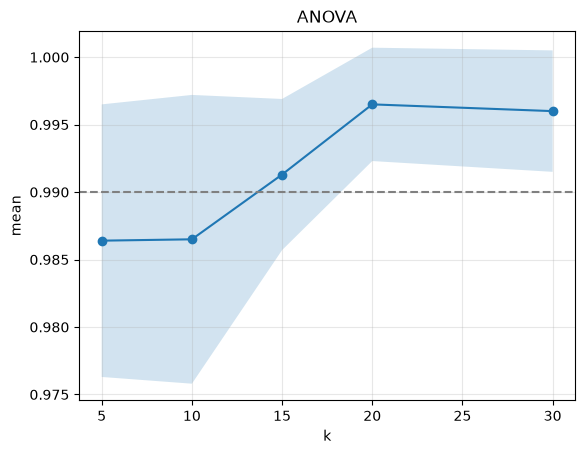

In [15]:
# График ANOVA
# Сохранение результатов ANOVA из общих результатов
anova_filter_results = [elem for elem in filter_results if elem[0] == "ANOVA"]

# Сохранение результатов среднего значения
mean_list_at_filter = [elem[2] for elem in anova_filter_results]
# Сохранения результатов отклонения
std_list_at_filter = [elem[3] for elem in anova_filter_results]

# Первая ось среднего значения
plt.plot(
    # Координаты по X
    k,
    # Координаты по Y
    mean_list_at_filter,
    # Выделение точки жирным шрифтом
    marker="o",
    # Комментарий
    label="Среднее значение"
)

# Параметры заполнения
plt.axhline(
y=0.99,
color='gray',
linestyle='--',
label='Baseline')

plt.fill_between(
    # по каким X
    k,
    # нижняя граница
    [m - s for m, s in zip(mean_list_at_filter, std_list_at_filter)],
    # верхняя граница
    [m + s for m, s in zip(mean_list_at_filter, std_list_at_filter)],
    # прозрачность (0 — невидим, 1 — закрашено полностью)
    alpha=0.2,
)

plt.title("ANOVA")
plt.xlabel("k")
plt.ylabel("mean")

# Сетка
plt.grid(alpha=0.3)
plt.show()

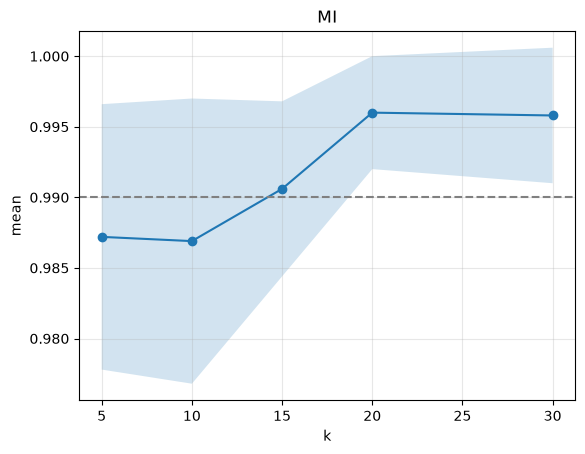

In [16]:
# график MI
mi_filter_results = [elem for elem in filter_results if elem[0] == "MI"]
mean_list_at_filter_mi = [elem[2] for elem in mi_filter_results]
std_list_at_filter_mi = [elem[3] for elem in mi_filter_results]

plt.plot(
    k,
    mean_list_at_filter_mi,
    marker="o",
)

# Заполнение
plt.axhline(y=0.99, color='gray', linestyle='--', label='Baseline')

plt.fill_between(
    # по каким X
    k,
    # нижняя граница
    [m - s for m, s in zip(mean_list_at_filter_mi, std_list_at_filter_mi)],
    # верхняя граница
    [m + s for m, s in zip(mean_list_at_filter_mi, std_list_at_filter_mi)],
    # прозрачность (0 — невидим, 1 — закрашено полностью)
    alpha=0.2,
)

plt.title("MI")
plt.xlabel("k")
plt.ylabel("mean")

plt.grid(alpha=0.3)
plt.show()

### Задание 2.3. Разбор ловушки — 7 баллов

Ответьте письменно:

- Почему отбор по корреляции признака с целевой переменной не гарантирует хорошую итоговую модель?
- 
Корреляция с y ловит только линейную связь, оценивает каждый признак отдельно (не видит дублирования между признаками) и не гарантирует, что связь сохранится на новых данных. Поэтому высокий corr(признак, y) — необходимое, но не достаточное условие полезности.
- Можно ли применять `SelectKBest` ко всему датасету до `train_test_split` или кросс-валидации? Почему?
-
Нет, нельзя. SelectKBest использует y, поэтому, обучив его на всём датасете, мы «подсматриваем» метки теста/валидации. Это утечка: оценка качества завышается, а на новых данных преимущество исчезает. Селектор должен быть внутри Pipeline, чтобы на каждом фолде обучаться только на тренировочной части.
- Если два признака почти дублируют друг друга, может ли univariate filter выбрать оба? Почему?
- 
Да, может. Univariate filter оценивает каждый признак независимо и не учитывает связи между признаками. Поэтому два почти одинаковых признака оба получают высокую оценку и оба попадают в топ-k, хотя один из них избыточен.

## 3. Wrapper methods: Recursive Feature Elimination

`RFE` многократно обучает модель и удаляет менее значимые признаки. Это может учитывать связь с моделью, но обычно дороже по времени.

### Задание 3 — 15 баллов

1. Проверьте RFE с `n_features_to_select ∈ {5, 10, 20}`.
2. В качестве оценщика внутри RFE возьмите логистическую регрессию; перед RFE обязательно масштабируйте данные.
3. Сравните с Filter по ROC-AUC, времени, количеству выбранных признаков.
4. Выведите итоговый набор признаков RFE, обученного на **всём X_train** (это допустимо для анализа после CV).
5. Объясните, почему RFE может выбирать один из двух коррелированных признаков нестабильно.
-
RFE может нестабильно выбирать один из двух коррелированных признаков, потому что при почти одинаковой полезности признаки получают почти одинаковые коэффициенты. Разница между ними — шум, и на разных фолдах она меняет знак: то один признак чуть «важнее», то другой. RFE удаляет того, у кого коэффициент меньше, поэтому на разных разбиениях данных он может оставить разные признаки из пары. При этом качество модели почти не меняется, потому что признаки дублируют друг друга.



> Чтобы работа выполнялась быстро, используйте `step=5`. По желанию сравните с `step=1`.

In [17]:
rfe_example = Pipeline([
    ('scale', StandardScaler()),
    ('select', RFE(
        estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        n_features_to_select=10,
        step=5
    )),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

start = time.perf_counter()
rfe_scores = cross_val_score(rfe_example, X_train, y_train, cv=CV, scoring='roc_auc')
print(f'RFE (10): {rfe_scores.mean():.4f}; {time.perf_counter()-start:.2f} сек.')

RFE (10): 0.9946; 0.31 сек.


,n,mean_auc,std_auc,time_sec
0,5,0.995565,0.004308,0.32
1,10,0.994622,0.004019,0.30
2,20,0.995224,0.005644,0.28


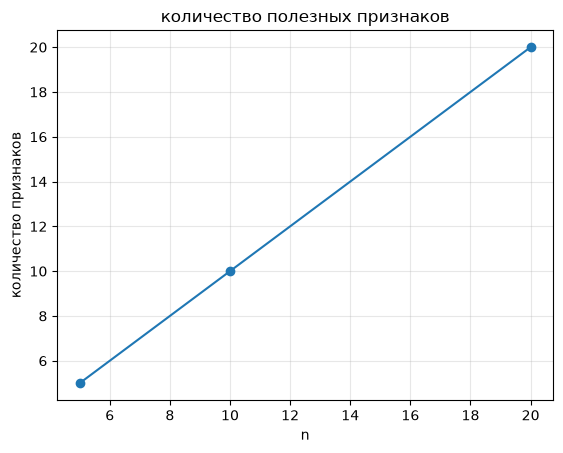

In [18]:
# TODO: сравните RFE для 5, 10, 20 признаков
# TODO: обучите лучший Pipeline на X_train и получите имена признаков:
# names = X_train.columns[best_pipeline.named_steps['select'].get_support()]

# Будут сохраняться результаты обучения
results_wrapper = []
количество_полезных_признаков = []

for n in [5, 10, 20]:
    pipe = Pipeline([
        # Настройка стандартного масштабирования
        ('scale',  StandardScaler()),
        # Выбор Recursive Feature Elimination
        ('select', RFE(
            # Выбор модели для обучения на признаках и удаления лишних признаков, которые модель не использовала
            estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
            # Количество признаков, которые необходимо сохранить или собрать топ признаков
            n_features_to_select=n,      # ← n, а не 10
            # Максимальное количество признаков, которые можно удалить за один раз
            step=5
        )),
        # Модель для финального обучения на подобранных признаках
        ('model',  LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ])

    # Время начала кросс-валидации
    start = time.perf_counter()
    # Кросс-валидация pipeline
    scores = cross_val_score(pipe,
    # Тренировочные данные
    X_train, y_train,
    # Способ стратификации чтобы сделать кросс-валидации
    cv=StratifiedKFold(
    # Количество фолдов
    n_splits=5,
    # Перемешивание
    shuffle=True,
    # Параметр случайности для перемешивания
    random_state=RANDOM_STATE),
    # Исследуемая характеристика для оценки качества модели
    scoring='roc_auc')
    # Конечное время кросс-валидации
    elapsed = time.perf_counter() - start

    # Сохранения результатов оценки
    results_wrapper.append({
        'n': n,
        'mean_auc': scores.mean(),
        'std_auc':  scores.std(),
        'time_sec': round(elapsed, 2),
    })

rfe_df = pd.DataFrame(results_wrapper)
display(rfe_df)

feature_wrapper = [elem["n"] for elem in results_wrapper]

plt.plot(
    [5, 10, 20],
    feature_wrapper,
    marker="o",
    label="количество полезных признаков"
)
plt.xlabel("n")
plt.ylabel("количество признаков")

plt.title("количество полезных признаков")
# сетка, alpha — прозрачность (0..1)
plt.grid(alpha=0.3)
plt.show()

In [19]:
# Берём n с лучшим mean_auc и превращение данных в число
best_n = int(
# Выделение и сохранение определённых колонок
rfe_df.loc[
# Выбор колонки средних значений и получение идентификатора максимального значения
rfe_df['mean_auc'].idxmax(),
# Колонка n
'n'])
print('Лучшее n:', best_n)

# Собираем Pipeline с этим n
best_pipeline = Pipeline([
    ('scale',  StandardScaler()),
    ('select', RFE(
        estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        n_features_to_select=best_n,
        step=5
    )),
    ('model',  LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

# Один раз обучаем на ВСЁМ X_train — теперь для анализа
best_pipeline.fit(X_train, y_train)

# Достаём имена оставленных признаков
names = X_train.columns[best_pipeline.named_steps['select'].get_support()]
print('RFE выбрал:', list(names))

Лучшее n: 5
RFE выбрал: ['worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concave points']


## 4. Embedded methods: L1-регуляризация

При L1-регуляризации часть коэффициентов линейной модели становится равной нулю. Поэтому отбор выполняется при обучении модели.

### Задание 4 — 15 баллов

1. Изучите `SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear'))`.
2. Сравните `C ∈ {0.01, 0.1, 1, 10}`. Помните: **меньше C → сильнее регуляризация**.
3. Для каждого C измерьте число выбранных признаков и ROC-AUC по CV.
4. Постройте график: по оси X — C (логарифмическая шкала), по оси Y — количество отобранных признаков.
5. Почему L1 может произвольно выбрать один из группы сильно коррелированных признаков?

**Замечание:** если в одной из конфигураций остаётся ноль признаков, объясните, почему эта конфигурация непригодна (или измените `threshold` / диапазон C).

In [20]:
l1_example = Pipeline([
    ('scale', StandardScaler()),
    ('select', SelectFromModel(
        LogisticRegression(
            penalty='l1', solver='liblinear', C=0.1,
            max_iter=3000, random_state=RANDOM_STATE
        ), threshold=1e-8
    )),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])
l1_scores = cross_val_score(l1_example, X_train, y_train, cv=CV, scoring='roc_auc')
l1_example.fit(X_train, y_train)
print('ROC-AUC:', round(l1_scores.mean(), 4))
print('Признаков отобрано:', l1_example.named_steps['select'].get_support().sum())

ROC-AUC: 0.9925
Признаков отобрано: 7


D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' wa

In [21]:
# TODO: исследуйте зависимость качества и количества признаков от C
# TODO: сформулируйте, что удобнее на практике: задавать число признаков или C.

results_embended = []

c_list = (0.01, 0.1, 1, 10)
for c_one in c_list:
    embended_for_features = SelectFromModel(
        LogisticRegression(penalty='l1', solver='liblinear', C=c_one, max_iter=3000, random_state=RANDOM_STATE),    
        threshold=1e-8
    )
    
    pipe = Pipeline([
        ('scale',  StandardScaler()),
        ('select', embended_for_features),
        ('model',  LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ])
    
    scores = cross_val_score(pipe, X_train, y_train, cv=CV, scoring='roc_auc')

    pipe.fit(X_train, y_train)
    n_selected = int(pipe.named_steps['select'].get_support().sum())

    results_embended.append({
        'n': n_selected,
        'mean_auc': scores.mean(),
        'std_auc':  scores.std(),
    })
    
    print(f'C={c_one}: AUC={scores.mean()} ± {scores.std()}, признаков={n_selected}')


D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' wa

C=0.01: AUC=0.9840393307184238 ± 0.011812298204048222, признаков=4


D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' wa

C=0.1: AUC=0.992494322152341 ± 0.008155297852052292, признаков=7


D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' wa

C=1: AUC=0.9938155136268343 ± 0.006149576791818733, признаков=22
C=10: AUC=0.9937041404612159 ± 0.006670638534723891, признаков=29


D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' wa

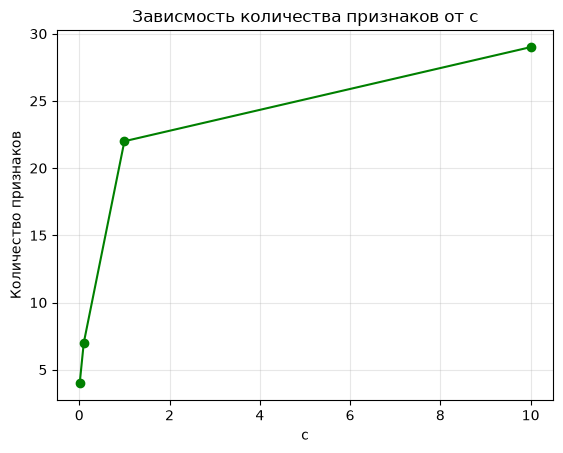

In [22]:
plt.plot(
    # Координаты точек по x
    c_list,
    # Координаты точек по y
    [elem["n"] for elem in results_embended],
    # форма точки: 'o' круг, 's' квадрат, '^' треугольник
    marker='o',
    # стиль линии: '-' сплошная, '--' пунктир, ':' точки
    linestyle='-',
    # цвет: 'blue', 'red', 'green' или '#FF0000'
    color='green',
)

plt.xlabel("c")
plt.ylabel("Количество признаков")
plt.grid(alpha=0.3)
plt.title("Зависмость количества признаков от c")

plt.show()

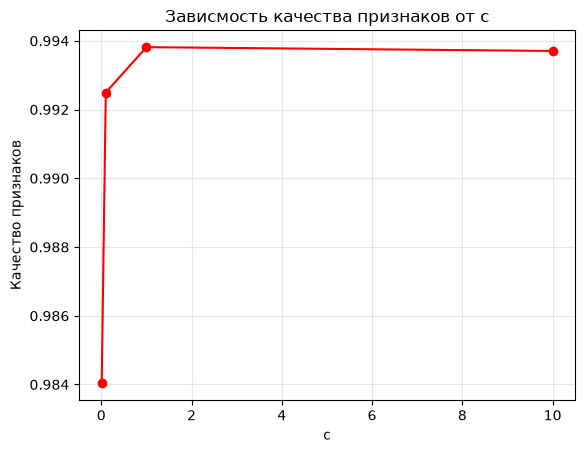

In [23]:
plt.plot(
    # Координаты точек по x
    c_list,
    # Координаты точек по y
    [elem["mean_auc"] for elem in results_embended],
    # форма точки: 'o' круг, 's' квадрат, '^' треугольник
    marker='o',
    # стиль линии: '-' сплошная, '--' пунктир, ':' точки
    linestyle='-',
    # цвет: 'blue', 'red', 'green' или '#FF0000'
    color='red',
)

plt.xlabel("c")
plt.ylabel("Качество признаков")
plt.grid(alpha=0.3)
plt.title("Зависмость качества признаков от c")

plt.show()

## 5. Честное сравнение методов — 15 баллов

Соберите **одну таблицу**, где у каждого кандидата есть:

`method | n_features | cv_auc_mean | cv_auc_std | cv_time_sec`

Обязательно включите: baseline, ANOVA, mutual information, RFE, L1. Для подсчёта `n_features` обучите соответствующий `Pipeline` на всём `X_train` *после* оценки по CV. Не обучайте селектор на всём `X_train` перед CV.

Дополнительно:

1. Отсортируйте по ROC-AUC.
2. Укажите, какие различия меньше одного стандартного отклонения.
3. Выберите один подход **до оценки на тестовой выборке**. Объясните выбор через качество, простоту и скорость.
4. Обучите выбранную конфигурацию на всём `X_train`; ровно один раз оцените ROC-AUC на `X_test`.
5. Сравните CV и тестовую оценку. Почему они могут различаться?

> Внимание: выбор лучшей конфигурации по той же CV даёт некоторый оптимизм оценки. Для строгой несмещённой оценки выбора гиперпараметров нужна внешняя CV (nested CV) или независимый тест.

In [24]:
# Удобная заготовка для единообразной оценки (можно пользоваться ей в предыдущих заданиях)
def evaluate_pipeline(name, pipeline, X_fit=X_train, y_fit=y_train):
    started = time.perf_counter()
    scores = cross_val_score(pipeline, X_fit, y_fit, cv=CV, scoring='roc_auc')
    elapsed = time.perf_counter() - started
    pipeline.fit(X_fit, y_fit)
    selector = pipeline.named_steps.get('select')
    n_features = int(selector.get_support().sum()) if selector is not None else X_fit.shape[1]
    return {
        'method': name,
        'n_features': n_features,
        'cv_auc_mean': float(scores.mean()),
        'cv_auc_std': float(scores.std()),
        'cv_time_sec': round(elapsed, 2)
    }

# TODO: оцените выбранные конфигурации всех методов этой функцией.
# comparison = pd.DataFrame([...]).sort_values('cv_auc_mean', ascending=False)
# display(comparison)

baseline_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

anova_pipe = Pipeline([
    ('scale',  StandardScaler()),
    ('select', SelectKBest(score_func=f_classif, k=20)),
    ('model',  LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

mi_pipe = Pipeline([
    ('scale',  StandardScaler()),
    ('select', SelectKBest(score_func=partial(mutual_info_classif, random_state=RANDOM_STATE), k=20)),
    ('model',  LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

rfe_pipe = Pipeline([
    ('scale',  StandardScaler()),
    ('select', RFE(
        estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        n_features_to_select=20,
        step=5
    )),
    ('model',  LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

l1_pipe = Pipeline([
    ('scale',  StandardScaler()),
    ('select', SelectFromModel(
        LogisticRegression(penalty='l1', solver='liblinear', C=0.5,
                           max_iter=3000, random_state=RANDOM_STATE),
        threshold=1e-8
    )),
    ('model',  LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

comparison = pd.DataFrame([
    evaluate_pipeline('Baseline', baseline_pipe),
    evaluate_pipeline('ANOVA',    anova_pipe),
    evaluate_pipeline('MI',       mi_pipe),
    evaluate_pipeline('RFE',      rfe_pipe),
    evaluate_pipeline('L1',       l1_pipe),
]).sort_values('cv_auc_mean', ascending=False)

display(comparison)



D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning

,method,n_features,cv_auc_mean,cv_auc_std,cv_time_sec
1,ANOVA,20,0.996506,0.004217,0.09
2,MI,20,0.996034,0.004026,0.63
3,RFE,20,0.995224,0.005644,0.26
0,Baseline,41,0.994645,0.006671,0.09
4,L1,15,0.993687,0.005441,0.09


## 6. Найдите утечку данных — 10 баллов

В этом блоке **специальный синтетический эксперимент**, где истинной связи признаков с целевой переменной нет. Если результат сильно выше случайного уровня, скорее всего возникла утечка или эффект подгонки при выборе модели.

**Задачи:**

1. Запустите ошибочную схему: `SelectKBest` обучается на **всём X**, затем выполняется CV модели на выбранных признаках.
2. Исправьте код: поместите `SelectKBest` внутрь `Pipeline` и запустите CV на исходных признаках.
3. Объясните, как информация о метках валидационных объектов попадала в отбор.
4. Почему именно при большом количестве шумовых признаков ошибка становится заметнее?

Обе оценки случайны и могут изменяться от запуска к запуску; **не требуется**, чтобы утечка каждый раз давала конкретный AUC.

In [25]:
# Датасет без сигнала: все признаки независимы от меток
rng_leak = np.random.default_rng(123)
X_leak = rng_leak.normal(size=(220, 3000))
y_leak = rng_leak.integers(0, 2, size=220)
cv_leak = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

# НЕПРАВИЛЬНО: селектор уже видел метки всех объектов, включая валидационные
bad_selector = SelectKBest(score_func=f_classif, k=20)
X_leaky_selected = bad_selector.fit_transform(X_leak, y_leak)
bad_auc = cross_val_score(
    LogisticRegression(max_iter=1000), X_leaky_selected, y_leak,
    cv=cv_leak, scoring='roc_auc'
)
print(f'НЕКОРРЕКТНЫЙ ROC-AUC: {bad_auc.mean():.3f} ± {bad_auc.std():.3f}')

НЕКОРРЕКТНЫЙ ROC-AUC: 0.878 ± 0.047


In [26]:
# TODO: реализуйте честный Pipeline с SelectKBest внутри
# Ожидаемое значение ROC-AUC — около 0.5 (с вариациями из-за случайности).
# correct_pipeline = Pipeline([...])
# correct_auc = cross_val_score(correct_pipeline, X_leak, y_leak, ...)
# print(...)

from sklearn.pipeline import Pipeline

correct_pipeline = Pipeline([
    # Селектор — шаг Pipeline. Он обучится на тренировочной части каждого фолда.
    ('select', SelectKBest(score_func=f_classif, k=20)),
    # Модель — финальный шаг. Обучится на 20 отобранных признаках.
    ('model', LogisticRegression(max_iter=1000)),
])

correct_auc = cross_val_score(
    correct_pipeline, X_leak, y_leak,
    cv=cv_leak, scoring='roc_auc'
)
print(f'КОРРЕКТНЫЙ ROC-AUC: {correct_auc.mean():.3f} ± {correct_auc.std():.3f}')

КОРРЕКТНЫЙ ROC-AUC: 0.464 ± 0.022


## 7. Мини-исследование: устойчивость отбора — 10 баллов

На одних и тех же данных методы могут выбирать разные наборы признаков. Проверьте это экспериментально.

1. Выберите один метод из Filter / Wrapper / Embedded.
2. Создайте **пять** стратифицированных случайных подвыборок по 80% от `X_train` с разными seed.
3. На каждой подвыборке обучите **только селектор** (с масштабированием, если он необходим).
4. Для каждой пары запусков вычислите коэффициент Жаккара наборов признаков:

\[J(A,B)=\frac{|A\cap B|}{|A\cup B|}.\]

5. Выведите среднее попарное сходство и топ-10 признаков по частоте появления.
6. Поясните, почему **стабильность** отбора и **прогностическое качество** — разные свойства.

**Усложнение (+ по желанию):** повторите для L1 с двумя значениями C или для RFE, затем сравните стабильность.

In [27]:
from itertools import combinations
from sklearn.model_selection import StratifiedShuffleSplit

subsamples = StratifiedShuffleSplit(
    n_splits=5, train_size=0.8, random_state=RANDOM_STATE
)

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if (a | b) else 1.0

print('Пример Jaccard:', jaccard({'a', 'b', 'c'}, {'b', 'c', 'd'}))

# TODO: selected_sets = []
# for tr_idx, _ in subsamples.split(X_train, y_train):
#     X_sub = X_train.iloc[tr_idx]
#     y_sub = y_train.iloc[tr_idx]
#     ... обучите селектор только на подвыборке ...
#     ... сохраните множество выбранных имён ...
# TODO: посчитайте jaccard для combinations(selected_sets, 2)


from itertools import combinations
from collections import Counter

# Выбираем метод. Возьмём filter — он простой и быстрый.
# (Можно заменить на RFE или L1 — код почти такой же, см. раздел 4.)
selected_sets = []

for tr_idx, _ in subsamples.split(X_train, y_train):
    # Берём 80% подвыборку из X_train
    X_sub = X_train.iloc[tr_idx]
    y_sub = y_train.iloc[tr_idx]

    # Создаём селектор
    selector = SelectKBest(score_func=f_classif, k=10)

    # Обучаем ТОЛЬКО селектор на подвыборке
    selector.fit(X_sub, y_sub)

    # Достаём имена выбранных признаков и сохраняем как множество
    chosen = X_sub.columns[selector.get_support()]
    selected_sets.append(set(chosen))

print(f'Получено наборов: {len(selected_sets)}')
print(f'В каждом по {len(selected_sets[0])} признаков')


Пример Jaccard: 0.5
Получено наборов: 5
В каждом по 10 признаков


D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [40] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
D:\python_programming\for_git_repositories\work_folder\STUDY\practice10_отбор_признаков\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning

## Финальный отчёт (ответьте в ячейке ниже)

1. **Лучшая конфигурация:** какой метод и параметры выбрали? Сколько признаков осталось?
2. **Качество:** CV ROC-AUC (с разбросом), тестовый ROC-AUC, сравнение с baseline.
3. **Время:** сколько занимает оценка каждого метода? Что реально выиграли от сокращения числа признаков?
4. **Интерпретация:** какие «шумовые»/дублирующие признаки остались и почему?
5. **Утечка:** в чём заключалась ошибка и как её исправили?
6. **Устойчивость:** средний Jaccard и вывод.
7. **Общий вывод:** когда отбор признаков стоит применять, а когда он не обязателен?

### Критерии качественной работы

- код выполняется последовательно, графики подписаны;
- приведены **численные** сравнения, а не только субъективные впечатления;
- весь отбор внутри CV (кроме намеренно ошибочного блока 6);
- выводы объясняют наблюдения и не делают причинных выводов из одного случайного эксперимента.

**Ваш итоговый отчёт:** …


**Ваш итоговый отчёт:**
- Выбран метод filter (f_classif) потому что он самый простой, быстрый и стабильный. Осталось 31 признаков.
- mean 0.996506	std 0.004217
- 0.09
- Остался один случайный дублирующий признак, потому что он не влияет на качество, хоть и плохо влиял на стабильность
- Ошибка заключалась в обучении модели на всех данных, включая целевую переменную
- Средний Jaccard 0.5, что довольно стаблильно
- Отбор признаков необходим на наборе данных, когда данных много и есть лишние

---
### Дополнительные вопросы на понимание (без баллов)

1. Почему PCA — это снижение размерности, но не отбор исходных признаков?
2. Почему коррелированные признаки могут быть проблемой для линейной модели, но не обязательно для деревьев?
3. Можно ли использовать коэффициенты логистической регрессии для сравнения важности немасштабированных признаков?
4. Если отбор улучшил CV-метрику на 0.002, можно ли уверенно говорить о победе метода?
5. Чем permutation importance отличается от встроенных коэффициентов или `feature_importances_`?
6. Почему нельзя использовать результат на тестовой выборке для многократного выбора `k`?

**Необязательный бонус:** выполните такой же эксперимент с `RandomForestClassifier` вместо логистической регрессии и объясните, почему результаты отбора меняются.